# Jak uczą się sieci neuronowe: spadek wzdłuż gradientu

**Plan notatnika:**
1. Przypomnienie i intuicja
2. Funkcja straty dwóch wag
3. Spadek wzdłuż gradientu krok po kroku
4. Wpływ współczynnika uczenia
5. Minima lokalne
6. Batch, SGD i mini-batch
7. Ulepszone optymalizatory: momentum i Adam
8. Podsumowanie

**Cele:**
- rozumieć, jak działa spadek wzdłuż gradientu i jaką rolę ma współczynnik uczenia,
- znać pojęcia: epoka, batch, iteracja, SGD, mini-batch,
- wiedzieć, czym różnią się optymalizatory (SGD, momentum, Adam),
- zrozumieć, że propagacja wsteczna to reguła łańcuchowa, a gradienty liczy za nas biblioteka.

## 1. Przypomnienie i intuicja

Spadek wzdłuż gradientu (*gradient descent*) znamy z rozdziału 3.1 (notatnik 02), gdzie szukaliśmy parametrów regresji liniowej. W sieciach neuronowych jest to **ten sam algorytm**, tylko parametrów jest znacznie więcej (tysiące, miliony, a w dużych modelach miliardy), a funkcja straty nie ma wzoru na wprost.

**Intuicja:** stoimy na zboczu góry we mgle i chcemy zejść do doliny. Nie widzimy całego terenu, ale czujemy nachylenie pod stopami. Robimy więc krok w stronę największego spadku i powtarzamy to wielokrotnie.

W języku matematyki: w każdym kroku aktualizujemy wagi w kierunku **przeciwnym do gradientu** funkcji straty $L$:

$$w \leftarrow w - \alpha \cdot \frac{\partial L}{\partial w}$$

gdzie $\alpha$ to **współczynnik uczenia** (*learning rate*) - wielkość kroku. Gradient wskazuje kierunek najszybszego wzrostu straty, więc idziemy w stronę przeciwną.

## 2. Funkcja straty dwóch wag

Dla zobrazowania weźmy najprostszą funkcję straty zależną od dwóch wag: $L(w_1, w_2) = w_1^2 + w_2^2$. Ma ona jedno minimum w punkcie $(0, 0)$, a jej wykres to paraboloida (miska).

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


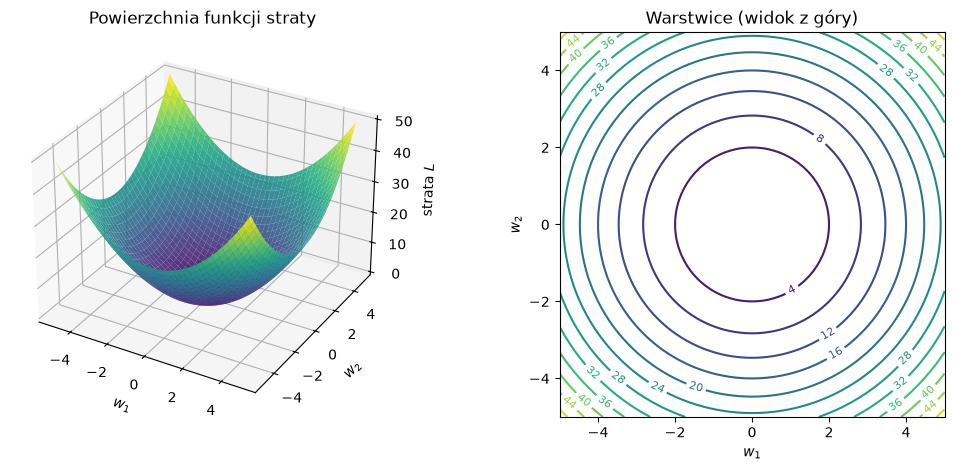

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def loss(w):
    return w[0] ** 2 + w[1] ** 2

def gradient(w):
    return np.array([2 * w[0], 2 * w[1]])

g1, g2 = np.meshgrid(np.linspace(-5, 5, 80), np.linspace(-5, 5, 80))
L = g1 ** 2 + g2 ** 2

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(g1, g2, L, cmap='viridis', alpha=0.9)
ax.set_xlabel('$w_1$')
ax.set_ylabel('$w_2$')
ax.set_zlabel('strata $L$')
ax.set_title('Powierzchnia funkcji straty')

ax2 = fig.add_subplot(1, 2, 2)
cs = ax2.contour(g1, g2, L, levels=15, cmap='viridis')
ax2.clabel(cs, inline=True, fontsize=8)
ax2.set_xlabel('$w_1$')
ax2.set_ylabel('$w_2$')
ax2.set_title('Warstwice (widok z góry)')
ax2.set_aspect('equal')
plt.show()

## 3. Spadek wzdłuż gradientu krok po kroku

Gradient funkcji $L$ to wektor pochodnych cząstkowych: $\nabla L = (2w_1,\, 2w_2)$. Zaczynamy w punkcie $(-4, 3)$ i wykonujemy 30 kroków ze współczynnikiem uczenia $\alpha = 0{,}1$.

In [2]:
def gradient_descent(grad, w0, lr, n_steps):
    w = np.array(w0, dtype=float)
    path = [w.copy()]
    for _ in range(n_steps):
        w = w - lr * grad(w)
        path.append(w.copy())
    return np.array(path)

path = gradient_descent(gradient, w0=[-4, 3], lr=0.1, n_steps=30)

history = pd.DataFrame({'w1': path[:, 0], 'w2': path[:, 1], 'strata': [loss(w) for w in path]})
print(history.iloc[[0, 1, 2, 3, 5, 10, 20, 30]].round(4))

        w1      w2   strata
0  -4.0000  3.0000  25.0000
1  -3.2000  2.4000  16.0000
2  -2.5600  1.9200  10.2400
3  -2.0480  1.5360   6.5536
5  -1.3107  0.9830   2.6844
10 -0.4295  0.3221   0.2882
20 -0.0461  0.0346   0.0033
30 -0.0050  0.0037   0.0000


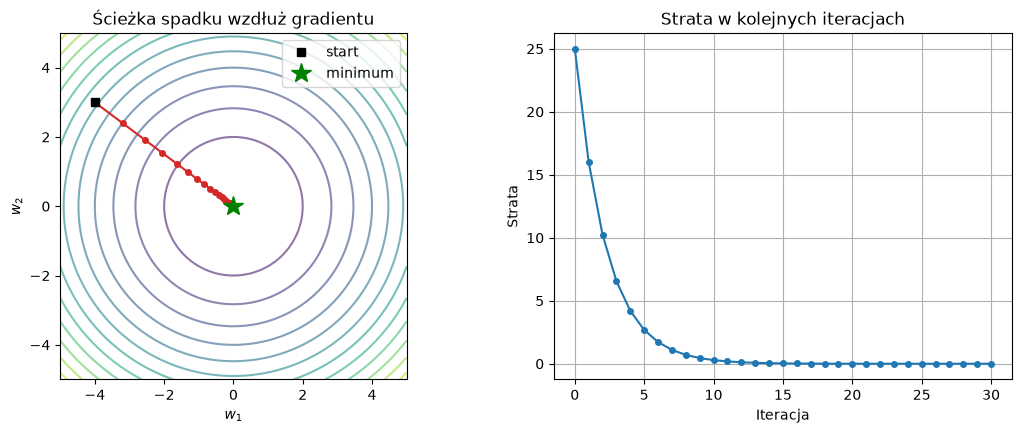

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].contour(g1, g2, L, levels=15, cmap='viridis', alpha=0.6)
axes[0].plot(path[:, 0], path[:, 1], 'o-', color='tab:red', markersize=4)
axes[0].plot(*path[0], 'ks', label='start')
axes[0].plot(0, 0, 'g*', markersize=15, label='minimum')
axes[0].set_xlabel('$w_1$')
axes[0].set_ylabel('$w_2$')
axes[0].set_title('Ścieżka spadku wzdłuż gradientu')
axes[0].legend()
axes[0].set_aspect('equal')

axes[1].plot(history['strata'], 'o-', markersize=4)
axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('Strata')
axes[1].set_title('Strata w kolejnych iteracjach')
axes[1].grid(True)
plt.show()

Kroki są największe na początku (gdzie powierzchnia jest stroma) i maleją wraz ze zbliżaniem się do minimum (gdzie gradient dąży do zera) - algorytm sam „zwalnia” przy dnie doliny.

## 4. Wpływ współczynnika uczenia

Współczynnik uczenia to **najważniejszy hiperparametr** treningu:
- **za mały** - uczenie jest bardzo wolne,
- **odpowiedni** - szybko zbiegamy do minimum,
- **za duży** - przeskakujemy minimum, a strata może rosnąć (rozbieżność).

Dla naszej funkcji aktualizacja ma postać $w \leftarrow (1 - 2\alpha)\, w$, więc zbieżność jest dla $0 < \alpha < 1$ (dla $\alpha = 0{,}5$ trafiamy w minimum w jednym kroku), a dla $\alpha > 1$ wagi rosną. Sprawdźmy to.

lr = 0.01: strata po 30 krokach = 7.439e+00
lr =  0.1: strata po 30 krokach = 3.831e-05
lr =  0.8: strata po 30 krokach = 1.222e-12
lr =  1.1: strata po 30 krokach = 1.409e+06


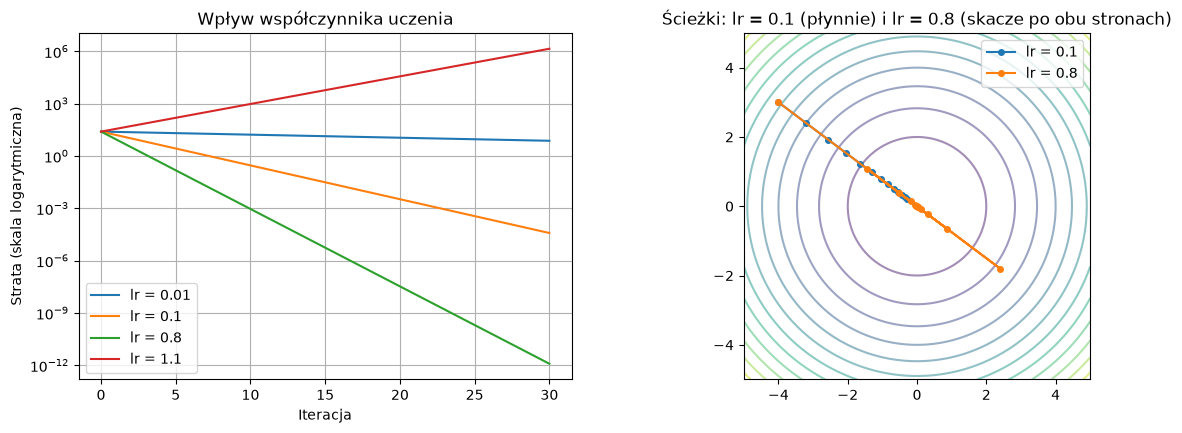

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for lr in [0.01, 0.1, 0.8, 1.1]:
    p = gradient_descent(gradient, w0=[-4, 3], lr=lr, n_steps=30)
    losses = [loss(w) for w in p]
    axes[0].plot(losses, label=f'lr = {lr}')
    print(f'lr = {lr:4}: strata po 30 krokach = {losses[-1]:.3e}')

axes[0].set_yscale('log')
axes[0].set_xlabel('Iteracja')
axes[0].set_ylabel('Strata (skala logarytmiczna)')
axes[0].set_title('Wpływ współczynnika uczenia')
axes[0].legend()
axes[0].grid(True)

axes[1].contour(g1, g2, L, levels=15, cmap='viridis', alpha=0.5)
for lr, color in [(0.1, 'tab:blue'), (0.8, 'tab:orange')]:
    p = gradient_descent(gradient, w0=[-4, 3], lr=lr, n_steps=12)
    axes[1].plot(p[:, 0], p[:, 1], 'o-', color=color, markersize=4, label=f'lr = {lr}')
axes[1].set_title('Ścieżki: lr = 0.1 (płynnie) i lr = 0.8 (skacze po obu stronach)')
axes[1].legend()
axes[1].set_aspect('equal')
plt.show()

- `lr = 0.01` - strata maleje, ale po 30 krokach jest jeszcze daleko od zera (za wolno),
- `lr = 0.1` - płynna zbieżność,
- `lr = 0.8` - algorytm przeskakuje minimum na drugą stronę w każdym kroku, ale nadal zbiega,
- `lr = 1.1` - strata **rośnie** (rozbieżność).

W praktyce typowe wartości dla optymalizatora Adam w Keras to $10^{-3}$ (domyślna) i okolice.

## 5. Minima lokalne

Funkcja kwadratowa ma jedno minimum, więc spadek zawsze do niego dojdzie. Funkcje straty prawdziwych sieci są dużo bardziej skomplikowane i mogą mieć wiele dolin. Zobaczmy to na funkcji jednej zmiennej $f(w) = w^4 - 3w^2 + w$ z dwoma minimami.

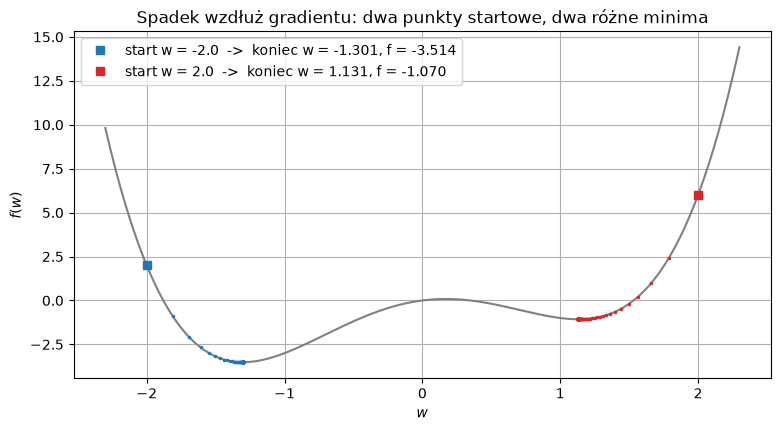

In [5]:
def f(w):
    return w ** 4 - 3 * w ** 2 + w

def df(w):
    return 4 * w ** 3 - 6 * w + 1

ws = np.linspace(-2.3, 2.3, 400)
plt.figure(figsize=(9, 4.5))
plt.plot(ws, f(ws), color='gray')

for w0, color in [(-2.0, 'tab:blue'), (2.0, 'tab:red')]:
    w = w0
    visited = [w]
    for _ in range(200):
        w = w - 0.01 * df(w)
        visited.append(w)
    visited = np.array(visited)
    plt.plot(visited, f(visited), '.', color=color, markersize=3)
    plt.plot(w0, f(w0), 's', color=color, label=f'start w = {w0}  ->  koniec w = {w:.3f}, f = {f(w):.3f}')

plt.xlabel('$w$')
plt.ylabel('$f(w)$')
plt.title('Spadek wzdłuż gradientu: dwa punkty startowe, dwa różne minima')
plt.legend()
plt.grid(True)
plt.show()

Algorytm startujący z lewej strony znajduje **minimum globalne**, a startujący z prawej - **minimum lokalne** (gorsze). Wynik zależy od punktu startowego, a w sieciach jest nim losowa inicjalizacja wag. Dlatego ustawiamy ziarno losowości dla powtarzalności, a przy poważnych zadaniach trenuje się model kilka razy z różnymi ziarnami.

## 6. Batch, SGD i mini-batch

Dotąd gradient liczyliśmy z wzoru na funkcję. W prawdziwym treningu strata zależy od **danych**: jest średnią błędów po obserwacjach. Mamy trzy sposoby liczenia gradientu:

| Wariant | Ile obserwacji na jedną aktualizację wag | Cechy |
|---|---|---|
| **Batch gradient descent** | wszystkie | dokładny gradient, ale 1 aktualizacja na epokę; wolne przy dużych danych |
| **Stochastic GD (SGD)** | 1 | bardzo szybkie, ale „szarpiące” aktualizacje |
| **Mini-batch GD** | paczka (np. 32, 64, 128) | kompromis; **standard w uczeniu głębokim** |

Słownik:
- **epoka** - jedno przejście przez cały zbiór treningowy,
- **batch size** - liczba obserwacji w jednej paczce,
- **iteracja** - jedna aktualizacja wag; liczba iteracji w epoce = liczba obserwacji / batch size.

Porównajmy wszystkie trzy warianty na prostych danych $y = 3x + 2 + \text{szum}$ (szum o odchyleniu 0,3). Uczymy dwa parametry: $w$ (powinno wyjść około 3) i $b$ (około 2).

In [6]:
rng = np.random.default_rng(42)
n = 1000
x = rng.uniform(-1, 1, n)
y = 3 * x + 2 + rng.normal(0, 0.3, n)

def train_linear(batch_size, lr, epochs=20, seed=0):
    rng = np.random.default_rng(seed)
    w, b = 0.0, 0.0
    mse_per_epoch = []
    n_updates = 0
    for _ in range(epochs):
        order = rng.permutation(n)                      # tasowanie na początku każdej epoki
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            error = w * x[idx] + b - y[idx]
            w -= lr * 2 * np.mean(error * x[idx])       # gradient MSE po w
            b -= lr * 2 * np.mean(error)                # gradient MSE po b
            n_updates += 1
        mse_per_epoch.append(np.mean((w * x + b - y) ** 2))
    return w, b, n_updates, mse_per_epoch

variants = {'batch (1000)': (n, 0.1), 'mini-batch (32)': (32, 0.1), 'SGD (1)': (1, 0.01)}
rows, curves = [], {}
for name, (bs, lr) in variants.items():
    w, b, n_updates, curve = train_linear(bs, lr)
    curves[name] = curve
    rows.append({'wariant': name, 'lr': lr, 'aktualizacji wag': n_updates,
                 'w': w, 'b': b, 'MSE po 20 epokach': curve[-1]})

print('Rozwiązanie dokładne (metoda najmniejszych kwadratów): w = %.3f, b = %.3f' % tuple(np.polyfit(x, y, 1)))
print('Wariancja szumu: %.3f' % 0.3 ** 2)
pd.DataFrame(rows).set_index('wariant').round(3)

Rozwiązanie dokładne (metoda najmniejszych kwadratów): w = 3.030, b = 1.977
Wariancja szumu: 0.090


,lr,aktualizacji wag,w,b,MSE po 20 epokach
wariant,,,,,
batch (1000),0.10,20,2.285,1.948,0.282
mini-batch (32),0.10,640,3.010,1.993,0.093
SGD (1),0.01,20000,3.008,1.993,0.093


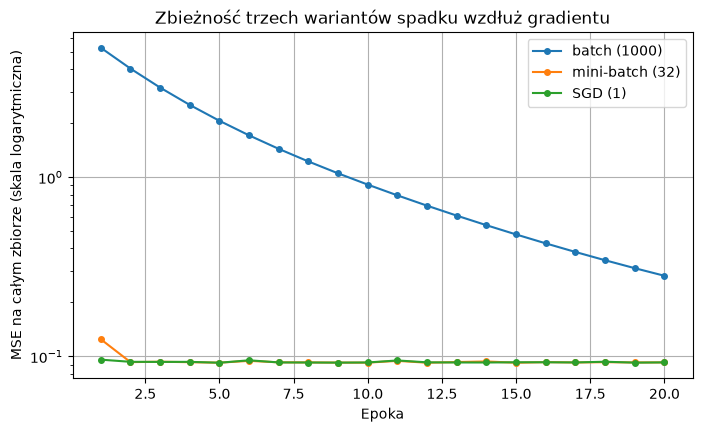

In [7]:
plt.figure(figsize=(8, 4.5))
for name, curve in curves.items():
    plt.plot(range(1, 21), curve, 'o-', markersize=4, label=name)
plt.yscale('log')
plt.xlabel('Epoka')
plt.ylabel('MSE na całym zbiorze (skala logarytmiczna)')
plt.title('Zbieżność trzech wariantów spadku wzdłuż gradientu')
plt.legend()
plt.grid(True)
plt.show()

- **Batch** wykonał w 20 epokach tylko 20 aktualizacji, więc nie zdążył zbiec - ma najwyższy błąd.
- **Mini-batch** (32 obserwacje) wykonał 640 aktualizacji i po kilku epokach jest już przy rozwiązaniu dokładnym.
- **SGD** wykonał 20 000 aktualizacji i także zbiegł, ale wymagał mniejszego `lr` (pojedyncza obserwacja daje „szumiący” gradient).
- Minimalny osiągalny błąd to w przybliżeniu wariancja szumu, bo szumu losowego nie da się przewidzieć.

W Keras wielkość paczki ustawiamy parametrem `batch_size` w `model.fit()` (domyślnie 32), a liczbę epok - parametrem `epochs`.

## 7. Ulepszone optymalizatory: momentum i Adam

Zwykły spadek wzdłuż gradientu ma problem w „wąskich dolinach”: gradient wskazuje głównie na ściany doliny, więc algorytm zygzakuje w poprzek, a wzdłuż doliny postępuje wolno. Popularne ulepszenia:

- **Momentum** - zapamiętuje poprzednie kierunki (jak ciężka kula toczona z górki): $v \leftarrow \beta v + \nabla L,\quad w \leftarrow w - \alpha v$. Zygzaki się znoszą, a ruch wzdłuż doliny przyspiesza.
- **Adam** - łączy momentum z **indywidualnym skalowaniem kroku dla każdej wagi** (waga o dużych gradientach dostaje mniejszy krok). W praktyce działa dobrze „z pudełka” i jest domyślnym wyborem w Keras.

Porównajmy je z podstawowym spadkiem na wydłużonej misce $L = w_1^2 + 100\,w_2^2$ (stromo w kierunku $w_2$, płasko w $w_1$). Każdy algorytm ma dobraną wielkość kroku, a zwykły spadek dostał największy możliwy, przy którym jeszcze nie jest rozbieżny.

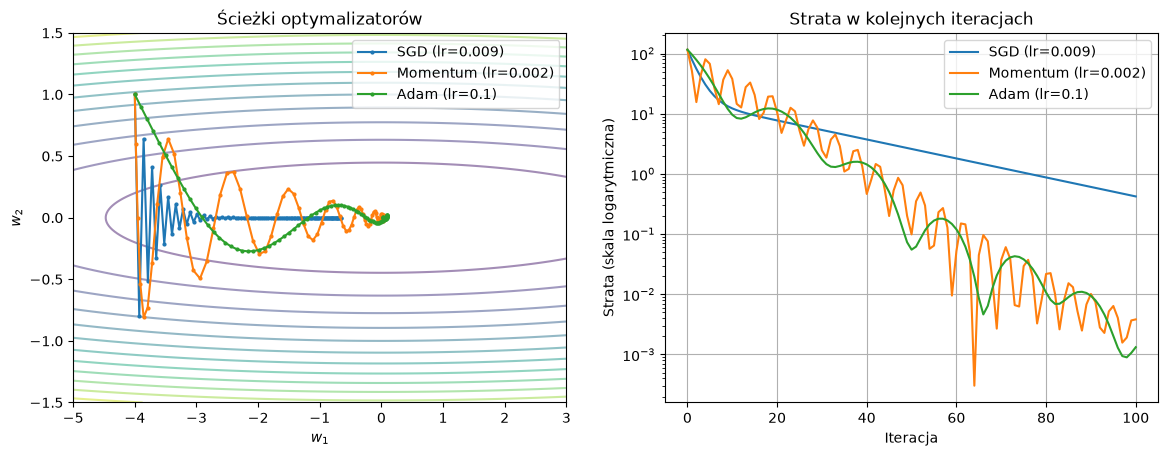

SGD (lr=0.009)         strata po 100 krokach: 0.4231
Momentum (lr=0.002)    strata po 100 krokach: 0.0038
Adam (lr=0.1)          strata po 100 krokach: 0.0013


In [7]:
A = np.array([1.0, 100.0])

def loss2(p):
    return A[0] * p[..., 0] ** 2 + A[1] * p[..., 1] ** 2

def grad2(p):
    return 2 * A * p

def run_sgd(p0, lr, steps):
    p, path = p0.copy(), [p0.copy()]
    for _ in range(steps):
        p = p - lr * grad2(p)
        path.append(p.copy())
    return np.array(path)

def run_momentum(p0, lr, steps, beta=0.9):
    p, v, path = p0.copy(), np.zeros(2), [p0.copy()]
    for _ in range(steps):
        v = beta * v + grad2(p)
        p = p - lr * v
        path.append(p.copy())
    return np.array(path)

def run_adam(p0, lr, steps, beta1=0.9, beta2=0.999, eps=1e-8):
    p, m, v, path = p0.copy(), np.zeros(2), np.zeros(2), [p0.copy()]
    for t in range(1, steps + 1):
        g = grad2(p)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g ** 2
        m_hat, v_hat = m / (1 - beta1 ** t), v / (1 - beta2 ** t)   # korekta początkowego obciążenia
        p = p - lr * m_hat / (np.sqrt(v_hat) + eps)
        path.append(p.copy())
    return np.array(path)

start = np.array([-4.0, 1.0])
steps = 100
paths = {
    'SGD (lr=0.009)': run_sgd(start, 0.009, steps),
    'Momentum (lr=0.002)': run_momentum(start, 0.002, steps),
    'Adam (lr=0.1)': run_adam(start, 0.1, steps),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
gx, gy = np.meshgrid(np.linspace(-5, 3, 200), np.linspace(-1.5, 1.5, 200))
axes[0].contour(gx, gy, A[0] * gx ** 2 + A[1] * gy ** 2, levels=15, cmap='viridis', alpha=0.5)
for (name, p), color in zip(paths.items(), ['tab:blue', 'tab:orange', 'tab:green']):
    axes[0].plot(p[:, 0], p[:, 1], '.-', color=color, markersize=4, label=name)
    axes[1].plot(loss2(p), color=color, label=name)
axes[0].set_xlabel('$w_1$')
axes[0].set_ylabel('$w_2$')
axes[0].set_title('Ścieżki optymalizatorów')
axes[0].legend()
axes[1].set_yscale('log')
axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('Strata (skala logarytmiczna)')
axes[1].set_title('Strata w kolejnych iteracjach')
axes[1].legend()
axes[1].grid(True)
plt.show()

for name, p in paths.items():
    print(f'{name:22s} strata po {steps} krokach: {loss2(p[-1]):.4f}')

Zwykły spadek jest ograniczony stromym kierunkiem $w_2$: większy krok powodowałby rozbieżność, więc w kierunku $w_1$ posuwa się powoli. Momentum i Adam co prawda oscylują (widać to na obu wykresach), ale po tej samej liczbie kroków osiągają stratę mniejszą o ponad dwa rzędy wielkości. Dlatego w praktyce zwykle zaczynamy od `optimizer='adam'`, a SGD z momentum (`keras.optimizers.SGD(momentum=0.9)`) stosuje się, gdy chcemy mieć większą kontrolę.

## 8. Podsumowanie

1. Uczenie sieci to **minimalizacja funkcji straty** przez spadek wzdłuż gradientu: $w \leftarrow w - \alpha \nabla L$.
2. **Współczynnik uczenia** decyduje o szybkości i stabilności: za mały - wolno, za duży - rozbieżność.
3. Funkcja straty sieci może mieć **minima lokalne**, więc wynik zależy od inicjalizacji wag.
4. W praktyce używamy **mini-batch**: epoka to przejście po wszystkich danych, a liczba iteracji w epoce to liczba obserwacji podzielona przez `batch_size`.
5. **Adam** (i momentum) przyspieszają uczenie w trudnych kształtach funkcji straty; Adam jest dobrym domyślnym optymalizatorem.
6. **Propagacja wsteczna** to reguła łańcuchowa; gradienty liczy automatycznie biblioteka (`tf.GradientTape`, wewnątrz `model.fit()`).